# LangGraph:

LangGraph is a framework for building AI agent workflows as graphs.

It allows you to define:
- State: Information shared throughout the workflow.
- Nodes: Individual tasks or functions.
- Edges: Connections that determine what runs next.
- Conditional edges: Decisions about which path to follow.
Think of LangGraph as a way to organize and control how an AI agent works.

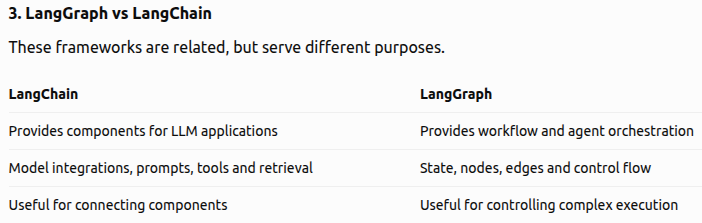

# LangGraph Architecture
A graph is a structure made of nodes and connections.

In LangGraph:
- A node performs a task.
- An edge connects one node to another.
- State carries information between nodes.
For example, consider a simple assistant:

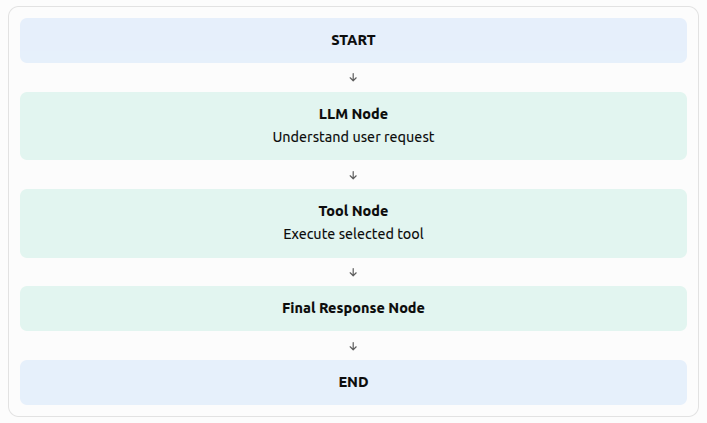



# State, Nodes and Edges
These are the three most important building blocks of LangGraph

# 1. State – Shared information : 
State stores information that different nodes in a graph can access and update.

Imagine the user asks:

What is 25 multiplied by 4?

Your graph might maintain this state:
state = {
    "user_query": "What is 25 multiplied by 4?",
    "tool_name": "calculator",
    "tool_result": 100,
    "final_answer": "25 multiplied by 4 is 100."
}
Each node can read relevant information from the state and return updates.

For example:
- LLM node reads user_query.
- Tool node reads tool_name and executes the calculator.
- Final response node reads tool_result.

# 2. Nodes – Individual tasks
A node is a Python function that performs a particular task.

For example:
def llm_node(state):
    print("Understanding user query")
    return state

    A node can:
- Read the current state.
- Perform an operation.
- Return updated state information.

# 3. Edges – Connections between nodes
An edge determines which node executes next.

For example: START → llm_node → calculator_node → response_node → END

# 4. Conditional edges
A normal edge follows a predefined path.

A conditional edge selects the next node based on a condition.

Example:
```text
             LLM Node
                 |
          Is a tool needed?
             /       \
           Yes        No
            |          |
        Tool Node   Response Node
            |          |
        Response Node  |
             \        /
                END
```

# too see the implementation see langGraph_first.py

this is working of the code: 
langgraph.graph: The module in the LangGraph library that contains the tools for building graphs.

StateGraph: The main class for building a graph where all nodes share one state. You give it your schema (State) so it knows what data the graph carries.

START: A special built-in marker meaning "the entry point of the graph." It is not a node you write. It just says where execution begins.

END: A special built-in marker meaning "the graph finishes here."

Builder: An object used to assemble the graph step by step. At this stage the graph is only a plan and cannot run yet.

add_node(name, function): Registers a node. The first argument is the name (a string) used to refer to the node, and the second is the Python function that runs when the node executes.

add_edge(from, to): Adds a connection saying "after from finishes, go to to." Edges define the order of execution.

compile(): Validates the graph (checks that nodes and edges are consistent) and turns the builder into a runnable graph object.

Working of the code
Import: StateGraph, START, and END are imported from langgraph.graph.
builder = StateGraph(State): Creates a new graph builder and tells it the shared state has the shape of your State class (number and result).
builder.add_node("double", double_number): Adds a node named "double". When this node runs, LangGraph calls your double_number function and passes it the current state.
builder.add_edge(START, "double"): Connects the entry point to the "double" node, so double is the first thing that runs.
builder.add_edge("double", END): Connects double to the end, so the graph finishes after double runs.
graph = builder.compile(): Produces the final runnable graph and stores it in graph.

# Conditional Routing in LangGraph
Conditional routing means choosing which node should execute next based on a condition.

For example, imagine Jarvis receives a request:
- "Calculate 25 × 4" → Calculator node.
- "Explain machine learning" → LLM node.
Instead of always executing the same node, the graph selects a path.

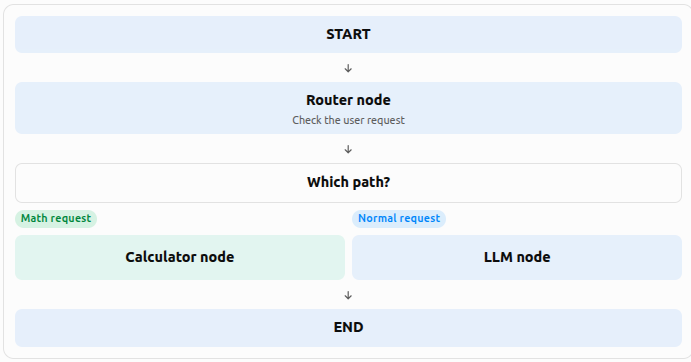

